<a href="https://colab.research.google.com/github/alberttrier/uk-house-price-forecasting/blob/main/uk_house_prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
print("hello")

hello


In [20]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/UK-HPI-full-file-2026-08.csv")
print(df.columns)
print(df.head())

df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
regions = ["London", "Scotland", "United Kingdom"]
df = df[df["RegionName"].isin(regions)]



Index(['Date', 'RegionName', 'AreaCode', 'AveragePrice', 'Index', 'IndexSA',
       '1m%Change', '12m%Change', 'AveragePriceSA', 'SalesVolume',
       'DetachedPrice', 'DetachedIndex', 'Detached1m%Change',
       'Detached12m%Change', 'SemiDetachedPrice', 'SemiDetachedIndex',
       'SemiDetached1m%Change', 'SemiDetached12m%Change', 'TerracedPrice',
       'TerracedIndex', 'Terraced1m%Change', 'Terraced12m%Change', 'FlatPrice',
       'FlatIndex', 'Flat1m%Change', 'Flat12m%Change', 'CashPrice',
       'CashIndex', 'Cash1m%Change', 'Cash12m%Change', 'CashSalesVolume',
       'MortgagePrice', 'MortgageIndex', 'Mortgage1m%Change',
       'Mortgage12m%Change', 'MortgageSalesVolume', 'FTBPrice', 'FTBIndex',
       'FTB1m%Change', 'FTB12m%Change', 'FOOPrice', 'FOOIndex', 'FOO1m%Change',
       'FOO12m%Change', 'NewPrice', 'NewIndex', 'New1m%Change',
       'New12m%Change', 'NewSalesVolume', 'OldPrice', 'OldIndex',
       'Old1m%Change', 'Old12m%Change', 'OldSalesVolume'],
      dtype='object

RegionName
London           2005-01-01
Scotland         2005-01-01
United Kingdom   2005-01-01
dtype: datetime64[ns]
RegionName
London            0
Scotland          0
United Kingdom    0
dtype: int64


<Axes: xlabel='Date'>

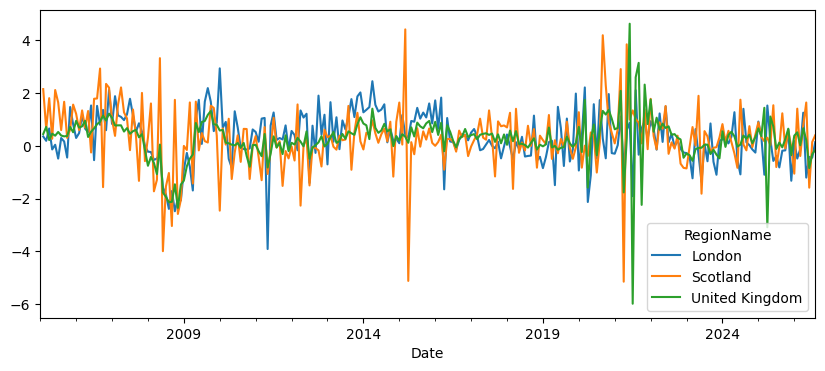

In [22]:
prices = df.pivot(index="Date", columns="RegionName", values="AveragePriceSA")
prices = prices.loc["2005-01-01":]

print(prices.apply(lambda s: s.first_valid_index()))
print(prices.isna().sum())

growth = np.log(prices).diff() * 100
growth.plot(figsize=(10, 4))

Lag-1 autocorrelation:
RegionName
London            0.217202
Scotland         -0.183726
United Kingdom    0.014416
dtype: float64


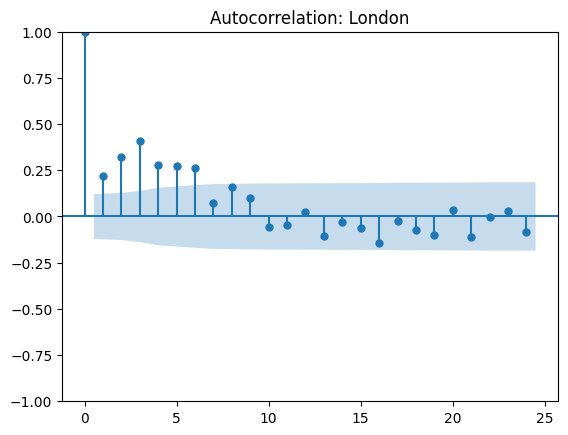

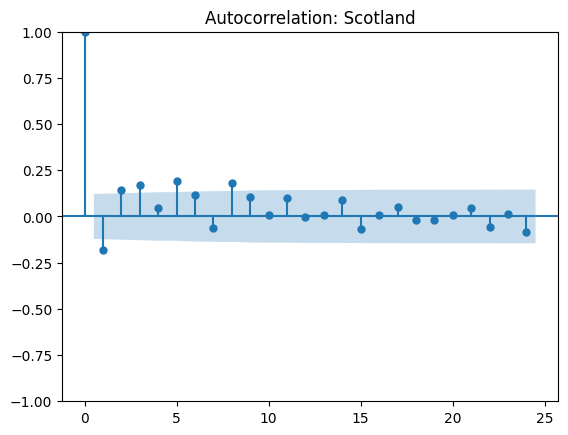

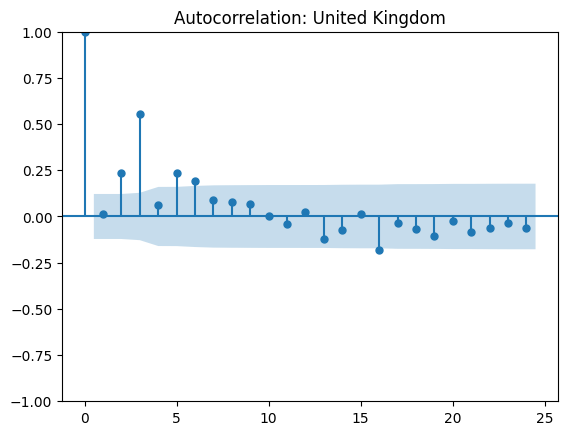

In [23]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

growth = growth.dropna()

print("Lag-1 autocorrelation:")
print(growth.apply(lambda s: s.autocorr(lag=1)))

for region in growth.columns:
  plot_acf(growth[region], lags=24, title=f"Autocorrelation: {region}")
  plt.show()


Observed lag-3: 0.5582483833330866
Share of shuffles at least this strong: 0.0


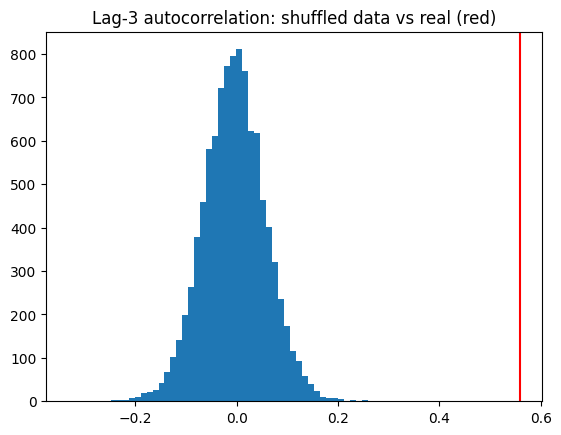

In [24]:
rng = np.random.default_rng(42)
s = growth["United Kingdom"]
observed = s.autocorr(lag=3)

fake = [pd.Series(rng.permutation(s.values)).autocorr(lag=3) for _ in range(10000)]
p_value = np.mean(np.abs(fake) >= abs(observed))

print("Observed lag-3:", observed)
print("Share of shuffles at least this strong:", p_value)

plt.hist(fake, bins=50)
plt.axvline(observed, color="red")
plt.title("Lag-3 autocorrelation: shuffled data vs real (red)")
plt.show()

In [25]:
from statsmodels.stats.diagnostic import acorr_ljungbox

for region in growth.columns:
  print(region)
  print(acorr_ljungbox(growth[region], lags=[3, 6, 12]))

London
       lb_stat     lb_pvalue
3    83.595053  5.196372e-18
6   142.731445  2.656925e-28
12  155.651741  4.032118e-27
Scotland
      lb_stat     lb_pvalue
3   21.645785  7.729167e-05
6   35.496887  3.452098e-06
12  50.892170  9.731964e-07
United Kingdom
       lb_stat     lb_pvalue
3    95.739552  1.280482e-20
6   121.158309  9.305923e-24
12  126.650200  2.897755e-21


In [26]:
def vol_aware_shuffle(series, n_groups, rng):

  vol = series.rolling(12, center=True, min_periods=6).std()
  groups = pd.qcut(vol, q=n_groups, labels=False)
  shuffled = series.copy()
  for g in range (n_groups):
    months = groups.index[groups == g]
    shuffled.loc[months] = rng.permutation(series.loc[months].values)
  return shuffled

for region in growth.columns:
  s = growth[region]
  observed = s.autocorr(lag=3)
  rng = np.random.default_rng(42)

  plain = [pd.Series(rng.permutation(s.values)).autocorr(lag=3) for _ in range(10000)]
  print(region, "| real lag-3:", round(observed, 3),
  "| plain shuffle p:", np.mean(np.abs(plain) >= abs(observed)))


  for n_groups in [2, 3, 4]:
    fake = [vol_aware_shuffle(s, n_groups, rng).autocorr(lag=3) for _ in range(10000)]
    print("  ", n_groups, "groups -> p:", np.mean(np.abs(fake) >= abs(observed)))




London | real lag-3: 0.408 | plain shuffle p: 0.0
   2 groups -> p: 0.0
   3 groups -> p: 0.0
   4 groups -> p: 0.0
Scotland | real lag-3: 0.171 | plain shuffle p: 0.0052
   2 groups -> p: 0.0152
   3 groups -> p: 0.0238
   4 groups -> p: 0.0321
United Kingdom | real lag-3: 0.558 | plain shuffle p: 0.0
   2 groups -> p: 0.0
   3 groups -> p: 0.0
   4 groups -> p: 0.0


In [27]:
!pip install duckdb -q
import duckdb

growth_long = growth.reset_index().melt(id_vars="Date", var_name="Region", value_name="Growth")
growth_long = growth_long.dropna()

duckdb.sql("SELECT * FROM growth_long LIMIT 5").show()


┌─────────────────────┬─────────┬──────────────────────┐
│        Date         │ Region  │        Growth        │
│    timestamp_ns     │ varchar │        double        │
├─────────────────────┼─────────┼──────────────────────┤
│ 2005-02-01 00:00:00 │ London  │  0.35329639510468525 │
│ 2005-03-01 00:00:00 │ London  │  0.18655864728884808 │
│ 2005-04-01 00:00:00 │ London  │   0.6551844282592256 │
│ 2005-05-01 00:00:00 │ London  │ -0.13966704382859518 │
│ 2005-06-01 00:00:00 │ London  │  0.03771345362970635 │
└─────────────────────┴─────────┴──────────────────────┘



In [28]:
duckdb.sql("""
SELECT Region,
       COUNT(*)       AS months,
       MIN(Date)      AS first_month,
       MAX(Date)      AS last_month,
       ROUND(AVG(Growth), 3)AS avg_growth
FROm growth_long
GROUP BY REGION
""").show()


┌────────────────┬────────┬─────────────────────┬─────────────────────┬────────────┐
│     Region     │ months │     first_month     │     last_month      │ avg_growth │
│    varchar     │ int64  │    timestamp_ns     │    timestamp_ns     │   double   │
├────────────────┼────────┼─────────────────────┼─────────────────────┼────────────┤
│ London         │    259 │ 2005-02-01 00:00:00 │ 2026-08-01 00:00:00 │      0.304 │
│ Scotland       │    259 │ 2005-02-01 00:00:00 │ 2026-08-01 00:00:00 │      0.283 │
│ United Kingdom │    259 │ 2005-02-01 00:00:00 │ 2026-08-01 00:00:00 │      0.253 │
└────────────────┴────────┴─────────────────────┴─────────────────────┴────────────┘



In [29]:
duckdb.sql("""
    SELECT Region,
           YEAR(Date)            AS year,
           ROUND(AVG(Growth), 2) AS avg_monthly_growth
    FROM growth_long
    GROUP BY Region, YEAR(Date)
    ORDER BY Region, year
""").df()

,Region,year,avg_monthly_growth
0,London,2005,0.26
1,London,2006,0.87
2,London,2007,1.00
3,London,2008,-1.32
4,London,2009,0.51
...,...,...,...
61,United Kingdom,2022,0.60
62,United Kingdom,2023,-0.23
63,United Kingdom,2024,0.28
64,United Kingdom,2025,0.14


In [30]:
duckdb.sql("""
    SELECT Region, Date, ROUND(Growth, 2) AS growth
    FROM growth_long
    ORDER BY Growth ASC
    LIMIT 15
""").show()

┌────────────────┬─────────────────────┬────────┐
│     Region     │        Date         │ growth │
│    varchar     │    timestamp_ns     │ double │
├────────────────┼─────────────────────┼────────┤
│ United Kingdom │ 2021-07-01 00:00:00 │  -5.99 │
│ Scotland       │ 2021-04-01 00:00:00 │  -5.15 │
│ Scotland       │ 2015-04-01 00:00:00 │  -5.12 │
│ Scotland       │ 2008-06-01 00:00:00 │  -3.99 │
│ London         │ 2011-05-01 00:00:00 │  -3.91 │
│ United Kingdom │ 2025-04-01 00:00:00 │  -3.09 │
│ Scotland       │ 2008-09-01 00:00:00 │  -3.04 │
│ Scotland       │ 2008-11-01 00:00:00 │  -2.58 │
│ London         │ 2008-10-01 00:00:00 │  -2.48 │
│ Scotland       │ 2010-01-01 00:00:00 │  -2.46 │
│ London         │ 2008-08-01 00:00:00 │  -2.39 │
│ United Kingdom │ 2008-11-01 00:00:00 │  -2.35 │
│ Scotland       │ 2012-04-01 00:00:00 │  -2.27 │
│ United Kingdom │ 2021-10-01 00:00:00 │  -2.24 │
│ United Kingdom │ 2008-08-01 00:00:00 │  -2.14 │
├────────────────┴─────────────────────┴────────┤


In [31]:
duckdb.sql("""
    SELECT Region, Date, ROUND(Growth, 2) AS growth,
        ROUND(LAG(Growth, 1) OVER (PARTITION BY Region ORDER BY Date), 2) AS prev_month,
        ROW_NUMBER() OVER (PARTITION BY Region ORDER BY Growth ASC)   AS worst_rank
    FROM growth_long
    QUALIFY worst_rank <= 5
    ORDER BY Region, worst_rank
""").show()

┌────────────────┬─────────────────────┬────────┬────────────┬────────────┐
│     Region     │        Date         │ growth │ prev_month │ worst_rank │
│    varchar     │    timestamp_ns     │ double │   double   │   int64    │
├────────────────┼─────────────────────┼────────┼────────────┼────────────┤
│ London         │ 2011-05-01 00:00:00 │  -3.91 │       1.05 │          1 │
│ London         │ 2008-10-01 00:00:00 │  -2.48 │      -1.72 │          2 │
│ London         │ 2008-08-01 00:00:00 │  -2.39 │      -1.84 │          3 │
│ London         │ 2020-04-01 00:00:00 │  -2.13 │       2.21 │          4 │
│ London         │ 2008-12-01 00:00:00 │  -2.07 │       -2.0 │          5 │
│ Scotland       │ 2021-04-01 00:00:00 │  -5.15 │        2.9 │          1 │
│ Scotland       │ 2015-04-01 00:00:00 │  -5.12 │       4.41 │          2 │
│ Scotland       │ 2008-06-01 00:00:00 │  -3.99 │       3.32 │          3 │
│ Scotland       │ 2008-09-01 00:00:00 │  -3.04 │      -1.03 │          4 │
│ Scotland  

In [32]:
duckdb.sql("""
    SELECT Region, Date,
        ROUND(Growth, 2) AS growth,
        ROUND(LEAD(Growth, 1) OVER (PARTITION BY Region ORDER BY Date), 2) AS next_month,
        ROUND(Growth + LEAD(Growth, 1) OVER (PARTITION BY Region ORDER BY Date), 2) AS two_month_sum,
        ROW_NUMBER() OVER (PARTITION BY Region ORDER BY ABS(Growth) DESC) AS size_rank
    FROM growth_long
    QUALIFY size_rank <= 8
    ORDER BY Region, Date
""").df()

,Region,Date,growth,next_month,two_month_sum,size_rank
0,London,2008-08-01,-2.39,-1.72,-4.11,5
1,London,2008-10-01,-2.48,-2.00,-4.49,3
2,London,2009-09-01,2.18,1.67,3.86,7
3,London,2010-01-01,2.93,0.68,3.61,2
4,London,2011-05-01,-3.91,0.77,-3.15,1
5,London,2014-04-01,2.44,1.55,4.00,4
6,London,2020-03-01,2.21,-2.13,0.08,6
7,London,2020-04-01,-2.13,-1.11,-3.24,8
8,Scotland,2008-05-01,3.32,-3.99,-0.68,7
9,Scotland,2008-06-01,-3.99,-1.55,-5.54,5


In [33]:
duckdb.sql("""
    SELECT Region, Date,
      ROUND(Growth, 2)            AS growth,
      ROUND(AVG(Growth) OVER w, 2) AS past12_avg,
      ROUND(STDDEV_SAMP(Growth) OVER w, 2) AS past12_sd,
      COUNT(Growth) OVER w        AS n_past
    FROM growth_long
    WINDOW w AS (PARTITION BY Region ORDER BY Date
    ROWS BETWEEN 12 PRECEDING AND 1 PRECEDING)

    QUALIFY Region = 'United Kingdom' AND Date BETWEEN '2021-01-01' AND '2021-12-01'
    ORDER BY Date
""").df()


,Region,Date,growth,past12_avg,past12_sd,n_past
0,United Kingdom,2021-01-01,0.62,0.56,0.93,12
1,United Kingdom,2021-02-01,0.67,0.56,0.93,12
2,United Kingdom,2021-03-01,2.08,0.63,0.89,12
3,United Kingdom,2021-04-01,-1.77,0.66,0.94,12
4,United Kingdom,2021-05-01,0.25,0.65,0.98,12
5,United Kingdom,2021-06-01,4.62,0.65,0.98,12
6,United Kingdom,2021-07-01,-5.99,0.96,1.51,12
7,United Kingdom,2021-08-01,2.59,0.50,2.50,12
8,United Kingdom,2021-09-01,3.14,0.66,2.58,12
9,United Kingdom,2021-10-01,-2.24,0.82,2.67,12


In [34]:
z = duckdb.sql("""
    WITH stats AS (
        SELECT Region, Date, Growth,
            AVG(Growth)         OVER w AS avg12,
            STDDEV_SAMP(Growth) OVER w AS sd12,
            COUNT(Growth)       OVER w AS n_past
    FROM growth_long
    WINDOW w AS (PARTITION BY Region ORDER BY Date
        ROWS BETWEEN 12 PRECEDING AND 1 PRECEDING)
)
SELECT Region, Date, Growth,
    (Growth - avg12) / sd12       AS z,
    ABS((Growth - avg12) / sd12) > 3 AS flagged
    FROM stats
    WHERE n_past = 12
""").df()

duckdb.sql("""
    SELECT Region, Date, ROUND(Growth, 2) AS growth, ROUND(z, 2) AS z
    FROM z
    WHERE flagged
    ORDER BY Region, Date
""").df()

,Region,Date,growth,z
0,London,2009-05-01,1.05,3.33
1,London,2009-06-01,1.74,3.09
2,London,2011-05-01,-3.91,-6.74
3,London,2012-07-01,-1.41,-3.73
4,London,2014-09-01,0.13,-3.85
5,London,2016-04-01,-1.65,-6.14
6,London,2018-10-01,1.14,3.83
7,Scotland,2006-10-01,-1.57,-3.26
8,Scotland,2010-01-01,-2.46,-3.12
9,Scotland,2013-08-01,1.51,3.92


In [35]:
duckdb.sql("""
SELECT Region,
    COUNT(*)                                 AS months,
    SUM(CASE WHEN flagged THEN 1 ELSE 0 END) AS n_flags,
    ROUND(AVG(ABS(z)), 2)                    AS avg_abs_z,
    ROUND(MAX(ABS(z)), 2)                    AS max_abs_z,
    ROUND(MAX(CASE WHEN YEAR(Date) IN (2008, 2009) THEN ABS(z) END), 2) AS max_abs_z_2008_2009
  FROM z
  GROUP BY Region
""").df()

,Region,months,n_flags,avg_abs_z,max_abs_z,max_abs_z_2008_2009
0,United Kingdom,247,13.0,1.1,9.17,4.42
1,Scotland,247,11.0,0.9,6.18,2.89
2,London,247,7.0,1.0,6.74,3.33


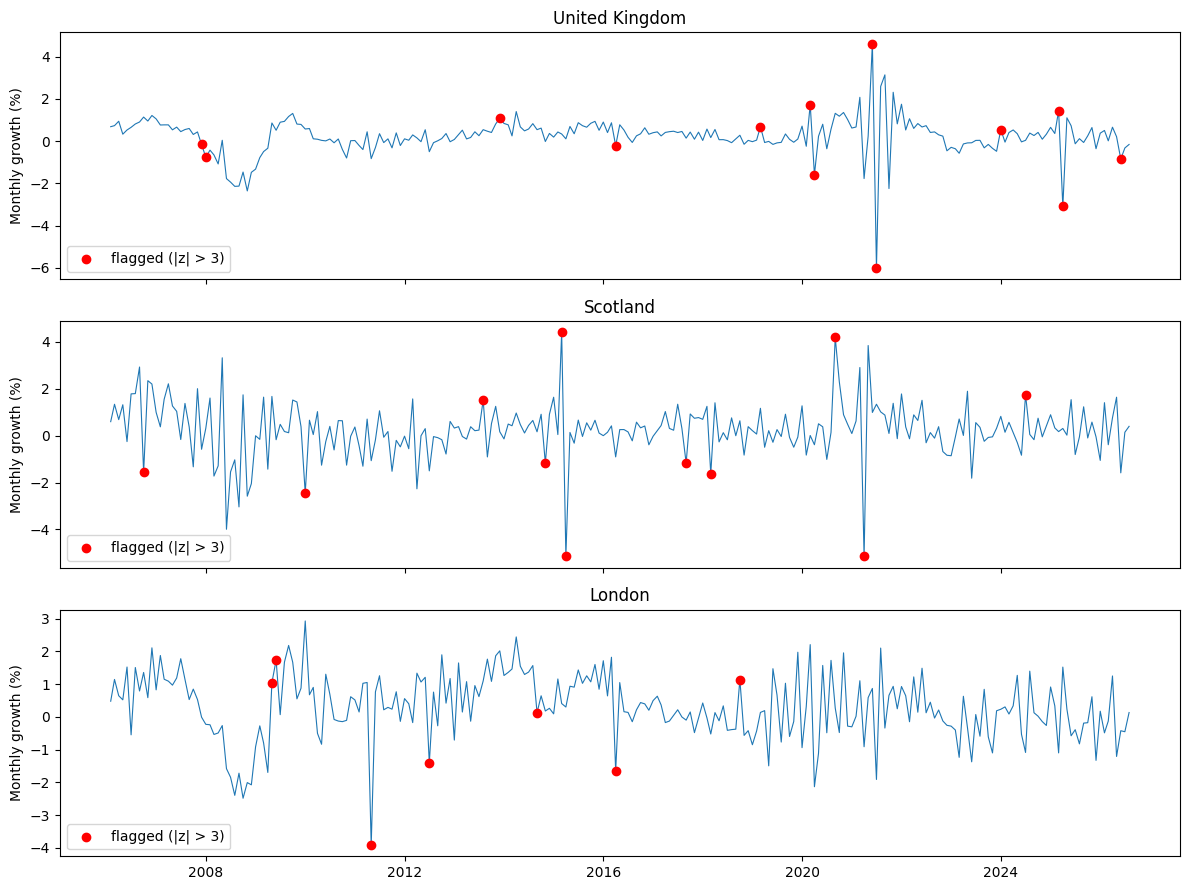

In [36]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for ax, region in zip(axes, z["Region"].unique()):
  d = z[z["Region"] == region]
  ax.plot(d["Date"], d["Growth"], linewidth=0.8)
  f = d[d["flagged"]]
  ax.scatter(f["Date"], f["Growth"], color="red", zorder=3, label="flagged (|z| > 3)")
  ax.set_title(region)
  ax.set_ylabel("Monthly growth (%)")
  ax.legend(loc="lower left")

plt.tight_layout()
plt.savefig("anomaly_flags.png", dpi=150)
plt.show()

In [37]:
def multi_lag_stat(s, max_lag=6):
    return sum(s.autocorr(lag=k) ** 2 for k in range(1, max_lag + 1))

for region in growth.columns:
    s = growth[region]
    observed = multi_lag_stat(s)
    rng = np.random.default_rng(42)
    fake = [multi_lag_stat(pd.Series(rng.permutation(s.values))) for _ in range(10000)]
    p = np.mean(np.array(fake) >= observed)
    print(region, "| combined lags 1-6:", round(observed, 3), "| shuffle p:", p)

London | combined lags 1-6: 0.545 | shuffle p: 0.0
Scotland | combined lags 1-6: 0.138 | shuffle p: 0.0
United Kingdom | combined lags 1-6: 0.463 | shuffle p: 0.0
